# 0-LIBRERIAS

In [2]:
import kagglehub
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split



# Configuración visual de gráficos
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

#1- IMPORTAR DATASET

In [3]:
#aquí se instala el dataset "Polycystic ovary syndrome (PCOS) directamente desde Kaggle"
path = kagglehub.dataset_download("prasoonkottarathil/polycystic-ovary-syndrome-pcos")
print("Path to dataset files:", path)

100%|██████████| 120k/120k [00:00<00:00, 1.09MB/s]

Extracting files...
Path to dataset files: C:\Users\eduar\.cache\kagglehub\datasets\prasoonkottarathil\polycystic-ovary-syndrome-pcos\versions\3


In [5]:
#En esta celda se asigna una ruta a los archivos descargados. Se descargan 2 con nombres PCOS_data_without_infertility.xlsx
# PCOS_data_without_infertility.xlsx y PCOS_infertility.csv. Sin embargo, para el alcance de este ejercicio
# sólo se utilizará PCOS_data_without_infertility.xlsx
file1 = os.listdir(path)[0]
file2 = os.listdir(path)[1]

path1 = path + "/" + file1
path2 = path + "/" + file2

df1 = pd.read_excel(path1, sheet_name=1, index_col=0)
df2 = pd.read_csv(path2, index_col=0)


In [6]:
#se echa un vistazo a los columnas y a la cantidad con la que se va a lidiar
print(f'Las columnas del dataset son: {df1.columns}')
print(f'La cantidad de columnas es: {len(df1)}')

Las columnas del dataset son: Index(['Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)',
       'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)',
       'Unnamed: 44'],
      dtype='object')
La cantidad de columnas es: 541


#2- DESCRIPCIÓN DE DATASET:

# Descripción de las variables del dataset PCOS

El dataset contiene información clínica, antropométrica, hormonal, reproductiva y de ultrasonido de pacientes, con el objetivo de analizar características relacionadas con el **Síndrome de Ovario Poliquístico (PCOS, por sus siglas en inglés)**.

A continuación se describe cada una de las variables utilizadas en el dataset.

---

## 1. Identificación de la paciente

### `Sl. No`
Número consecutivo asignado a cada registro dentro del dataset. Esta variable funciona únicamente como identificador y no contiene información clínica relevante para la predicción.

### `Patient File No.`
Número de expediente o identificador de la paciente. Se utiliza para identificar cada registro, pero no representa una característica clínica. Por esta razón, normalmente debe excluirse de los modelos de Machine Learning.

---

## 2. Variable objetivo

### `PCOS (Y/N)`
Indica si la paciente presenta o no Síndrome de Ovario Poliquístico.

- `1` = La paciente presenta PCOS.
- `0` = La paciente no presenta PCOS.

Esta variable puede utilizarse como **variable objetivo (target)** en un problema de clasificación binaria.

---

## 3. Características demográficas y antropométricas

### `Age (yrs)`
Edad de la paciente expresada en años.

### `Weight (Kg)`
Peso corporal de la paciente expresado en kilogramos.

### `Height(Cm)`
Altura de la paciente expresada en centímetros.

### `BMI`
Índice de Masa Corporal (Body Mass Index). Es una medida que relaciona el peso y la altura de una persona y puede calcularse mediante:

$$
BMI = \frac{Weight(kg)}{Height(m)^2}
$$

### `Blood Group`
Grupo sanguíneo de la paciente. Aunque los valores pueden estar representados mediante códigos numéricos, esta variable debe considerarse como una variable categórica y no como una variable numérica continua.

---

## 4. Signos vitales y parámetros hematológicos

### `Pulse rate(bpm)`
Frecuencia cardíaca de la paciente, expresada en latidos por minuto (beats per minute, bpm).

### `RR (breaths/min)`
Frecuencia respiratoria de la paciente, expresada como el número de respiraciones por minuto.

### `Hb(g/dl)`
Concentración de hemoglobina en sangre, expresada en gramos por decilitro (g/dL).

---

## 5. Características del ciclo menstrual y reproductivas

### `Cycle(R/I)`
Indica la regularidad del ciclo menstrual.

- `R` = Ciclo regular.
- `I` = Ciclo irregular.

Es una variable categórica que puede ser relevante para la identificación de alteraciones asociadas con PCOS.

### `Cycle length(days)`
Duración registrada del ciclo menstrual, expresada en días.

### `Marraige Status (Yrs)`
Número de años transcurridos desde el matrimonio de la paciente. A pesar del nombre de la variable, representa una cantidad de años y no únicamente el estado civil.

### `Pregnant(Y/N)`
Indica si la paciente está embarazada.

- `1` = Sí.
- `0` = No.

### `No. of aborptions`
Número de abortos registrados para la paciente.

---

## 6. Parámetros hormonales

### `I beta-HCG(mIU/mL)`
Primer valor registrado de beta-hCG (gonadotropina coriónica humana), expresado en mIU/mL. Esta hormona está principalmente asociada con el embarazo.

### `II beta-HCG(mIU/mL)`
Segundo valor registrado de beta-hCG, expresado en mIU/mL.

### `FSH(mIU/mL)`
Concentración de la hormona foliculoestimulante (Follicle-Stimulating Hormone, FSH), expresada en mIU/mL. Esta hormona participa en la regulación del desarrollo de los folículos ováricos y del ciclo reproductivo.

### `LH(mIU/mL)`
Concentración de la hormona luteinizante (Luteinizing Hormone, LH), expresada en mIU/mL. Esta hormona participa en la regulación de la ovulación y del ciclo menstrual.

### `FSH/LH`
Relación entre las concentraciones de FSH y LH. Se calcula mediante:

$$
FSH/LH = \frac{FSH}{LH}
$$

Es una variable derivada a partir de otras dos variables hormonales.

### `TSH (mIU/L)`
Concentración de la hormona estimulante de la tiroides (Thyroid-Stimulating Hormone, TSH), expresada en mIU/L.

### `AMH(ng/mL)`
Concentración de hormona antimülleriana (Anti-Müllerian Hormone, AMH), expresada en ng/mL. Esta hormona está relacionada con la función ovárica y el desarrollo de los folículos.

### `PRL(ng/mL)`
Concentración de prolactina en sangre, expresada en ng/mL.

### `Vit D3 (ng/mL)`
Concentración de vitamina D3, expresada en ng/mL.

### `PRG(ng/mL)`
Concentración de progesterona, expresada en ng/mL. La progesterona es una hormona importante en la regulación del ciclo menstrual y la función reproductiva.

### `RBS(mg/dl)`
Nivel de glucosa en sangre medido de manera aleatoria (Random Blood Sugar), expresado en mg/dL.

---

## 7. Medidas antropométricas adicionales

### `Weight gain(Y/N)`
Indica si la paciente ha experimentado aumento de peso.

- `1` = Sí.
- `0` = No.

### `hair growth(Y/N)`
Indica la presencia de crecimiento excesivo de vello corporal o facial.

- `1` = Sí.
- `0` = No.

### `Skin darkening (Y/N)`
Indica la presencia de oscurecimiento de la piel.

- `1` = Sí.
- `0` = No.

### `Hair loss(Y/N)`
Indica si la paciente presenta pérdida de cabello.

- `1` = Sí.
- `0` = No.

### `Pimples(Y/N)`
Indica la presencia de acné o granos.

- `1` = Sí.
- `0` = No.

### `Hip(inch)`
Circunferencia de la cadera de la paciente, expresada en pulgadas.

### `Waist(inch)`
Circunferencia de la cintura de la paciente, expresada en pulgadas.

### `Waist:Hip Ratio`
Relación entre la circunferencia de la cintura y la circunferencia de la cadera:

$$
Waist:Hip\ Ratio = \frac{Waist}{Hip}
$$

Esta variable proporciona información sobre la distribución de la grasa corporal.

---

## 8. Hábitos y estilo de vida

### `Fast food (Y/N)`
Indica si la paciente consume comida rápida.

- `1` = Sí.
- `0` = No.

### `Reg.Exercise(Y/N)`
Indica si la paciente realiza ejercicio de manera regular.

- `1` = Sí.
- `0` = No.

---

## 9. Presión arterial

### `BP _Systolic (mmHg)`
Presión arterial sistólica de la paciente, expresada en mmHg. Representa la presión arterial durante la contracción del corazón.

### `BP _Diastolic (mmHg)`
Presión arterial diastólica de la paciente, expresada en mmHg. Representa la presión arterial durante la relajación del corazón.

---

## 10. Características obtenidas mediante ultrasonido

### `Follicle No. (L)`
Número de folículos observados en el ovario izquierdo durante la evaluación por ultrasonido.

`L` corresponde a *Left* (izquierdo).

### `Follicle No. (R)`
Número de folículos observados en el ovario derecho durante la evaluación por ultrasonido.

`R` corresponde a *Right* (derecho).

### `Avg. F size (L) (mm)`
Tamaño promedio de los folículos observados en el ovario izquierdo, expresado en milímetros.

### `Avg. F size (R) (mm)`
Tamaño promedio de los folículos observados en el ovario derecho, expresado en milímetros.

### `Endometrium (mm)`
Grosor del endometrio observado durante la evaluación por ultrasonido, expresado en milímetros.

---

## Consideraciones para el modelo

Al utilizar este dataset para desarrollar un modelo de clasificación, algunas variables requieren un tratamiento especial.

Las variables `Sl. No` y `Patient File No.` funcionan como identificadores y normalmente deben eliminarse, ya que no proporcionan información clínica útil para la predicción.

Por otro lado, variables como `BMI`, `FSH/LH` y `Waist:Hip Ratio` son variables derivadas, ya que pueden calcularse a partir de otras variables presentes en el dataset.

Finalmente, las variables binarias como `PCOS (Y/N)`, `Pregnant(Y/N)`, `Weight gain(Y/N)`, `hair growth(Y/N)`, `Skin darkening (Y/N)`, `Hair loss(Y/N)`, `Pimples(Y/N)`, `Fast food (Y/N)` y `Reg.Exercise(Y/N)` representan respuestas de tipo sí/no y pueden codificarse numéricamente para su utilización en modelos de Machine Learning.

### 2-ANÁLISIS EXPLORATORIO

In [75]:
# Se hace un primer vistazo del dataset y sus dimensiones


display(df1.head())

print("\nDimensiones del dataset:")
print(df1.shape)

print("\nNombres de las columnas:")
print(df1.columns.tolist())

,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
Sl. No,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1,0,28,44.6,152.0,19.300000,15,78,22,10.48,2,5,7.0,0,0,1.99,1.99,7.95,3.68,2.160326,36,30,0.833333,0.68,2.07,45.16,17.1,0.57,92.0,0,0,0,0,0,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
2,2,0,36,65.0,161.5,24.921163,15,74,20,11.70,2,5,11.0,1,0,60.80,1.99,6.73,1.09,6.174312,38,32,0.842105,3.16,1.53,20.09,61.3,0.97,92.0,0,0,0,0,0,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
3,3,1,33,68.8,165.0,25.270891,11,72,18,11.80,2,5,10.0,1,0,494.08,494.08,5.54,0.88,6.295455,40,36,0.900000,2.54,6.63,10.52,49.7,0.36,84.0,0,0,0,1,1,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
4,4,0,37,65.0,148.0,29.674945,13,72,20,12.00,2,5,4.0,0,0,1.99,1.99,8.06,2.36,3.415254,42,36,0.857143,16.41,1.22,36.90,33.4,0.36,76.0,0,0,0,0,0,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
5,5,0,25,52.0,161.0,20.060954,11,72,18,10.00,2,5,1.0,1,0,801.45,801.45,3.98,0.90,4.422222,37,30,0.810811,3.57,2.26,30.09,43.8,0.38,84.0,0,0,0,1,0,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN



Dimensiones del dataset:
(541, 44)

Nombres de las columnas:
['Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)', 'Unnamed: 44']


In [76]:
# Aquí se aprecia el tipo de dato asignado a cada columna. Aquí de entrada podemos ver si hay valores faltantes
# y si existe incongruencia entre el tipo de dato y el valor que representa.

df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 541 entries, 1 to 541
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient File No.        541 non-null    int64  
 1   PCOS (Y/N)              541 non-null    int64  
 2    Age (yrs)              541 non-null    int64  
 3   Weight (Kg)             541 non-null    float64
 4   Height(Cm)              541 non-null    float64
 5   BMI                     541 non-null    float64
 6   Blood Group             541 non-null    int64  
 7   Pulse rate(bpm)         541 non-null    int64  
 8   RR (breaths/min)        541 non-null    int64  
 9   Hb(g/dl)                541 non-null    float64
 10  Cycle(R/I)              541 non-null    int64  
 11  Cycle length(days)      541 non-null    int64  
 12  Marraige Status (Yrs)   540 non-null    float64
 13  Pregnant(Y/N)           541 non-null    int64  
 14  No. of aborptions       541 non-null    int64  

In [77]:
# ESTADÍSTICA DESCRIPTIVA
display(df1.describe().T)

,count,mean,std,min,25%,50%,75%,max
Patient File No.,541.0,271.000000,156.317519,1.000000,136.000000,271.000000,406.000000,541.000000
PCOS (Y/N),541.0,0.327172,0.469615,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
Weight (Kg),541.0,59.637153,11.028287,31.000000,52.000000,59.000000,65.000000,108.000000
Height(Cm),541.0,156.484835,6.033545,137.000000,152.000000,156.000000,160.000000,180.000000
BMI,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Blood Group,541.0,13.802218,1.840812,11.000000,13.000000,14.000000,15.000000,18.000000
Pulse rate(bpm),541.0,73.247689,4.430285,13.000000,72.000000,72.000000,74.000000,82.000000
RR (breaths/min),541.0,19.243993,1.688629,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),541.0,11.160037,0.866904,8.500000,10.500000,11.000000,11.700000,14.800000


In [78]:
# Se revisa puntualmente los valores faltantes. Un hallazgo es que existe una columna sin datos (solo tiene un par)
#accidentales y en 2 columnas sólo falta un valor. Más adelante se optará por borrar Unnamed: 44 que sabemos que
#no sirve de nada y con un imputador se agregará el valor faltante para Marriage Status y Fast Food.


missing = pd.DataFrame({
    'Missing Values': df1.isnull().sum(),
    'Percentage': df1.isnull().mean() * 100
})

missing = missing.sort_values(
    'Percentage',
    ascending=False
)

display(missing)

,Missing Values,Percentage
Unnamed: 44,539,99.630314
Marraige Status (Yrs),1,0.184843
Fast food (Y/N),1,0.184843
PRL(ng/mL),0,0.000000
Vit D3 (ng/mL),0,0.000000
PRG(ng/mL),0,0.000000
RBS(mg/dl),0,0.000000
Weight gain(Y/N),0,0.000000
hair growth(Y/N),0,0.000000
Skin darkening (Y/N),0,0.000000


In [79]:
# Se revisa si existe valores duplicados

duplicates = df1.duplicated().sum()

print(f"Número de filas duplicadas: {duplicates}")
print(f"Porcentaje de duplicados: {duplicates / len(df1) * 100:.2f}%")

Número de filas duplicadas: 0
Porcentaje de duplicados: 0.00%


In [80]:

# Se categoriza los datos según si son numéricos o categóricos. (más adelante se cambiarán algunos que no cuadran)

numeric_cols = df1.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df1.select_dtypes(
    exclude=np.number
).columns.tolist()

print("VARIABLES NUMÉRICAS:")
print(numeric_cols)

print("\nVARIABLES CATEGÓRICAS:")
print(categorical_cols)

VARIABLES NUMÉRICAS:
['Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

VARIABLES CATEGÓRICAS:
['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)', 'Unnamed: 44']


In [81]:
#  Se revisan VALORES ÚNICOS

unique_values = pd.DataFrame({
    'Variable': df1.columns,
    'Unique Values': [
        df1[col].nunique(dropna=False)
        for col in df1.columns
    ]
})

display(
    unique_values.sort_values(
        'Unique Values'
    )
)

,Variable,Unique Values
1,PCOS (Y/N),2
30,hair growth(Y/N),2
31,Skin darkening (Y/N),2
32,Hair loss(Y/N),2
33,Pimples(Y/N),2
13,Pregnant(Y/N),2
29,Weight gain(Y/N),2
35,Reg.Exercise(Y/N),2
43,Unnamed: 44,3
34,Fast food (Y/N),3


In [82]:
#  DISTRIBUCIÓN DEL TARGET

target = 'PCOS (Y/N)'

print("Distribución de PCOS:")
display(df1[target].value_counts())

print("\nPorcentaje:")
display(
    df1[target].value_counts(normalize=True) * 100
)

Distribución de PCOS:


PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64


Porcentaje:


PCOS (Y/N)
0    67.28281
1    32.71719
Name: proportion, dtype: float64

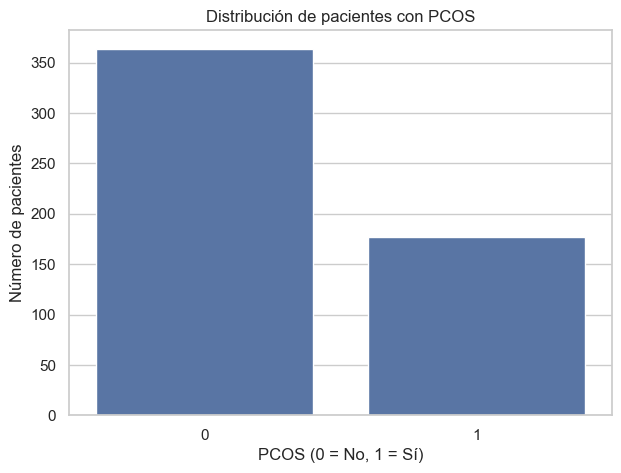

In [83]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df1,
    x=target
)

plt.title('Distribución de pacientes con PCOS')
plt.xlabel('PCOS (0 = No, 1 = Sí)')
plt.ylabel('Número de pacientes')

plt.show()

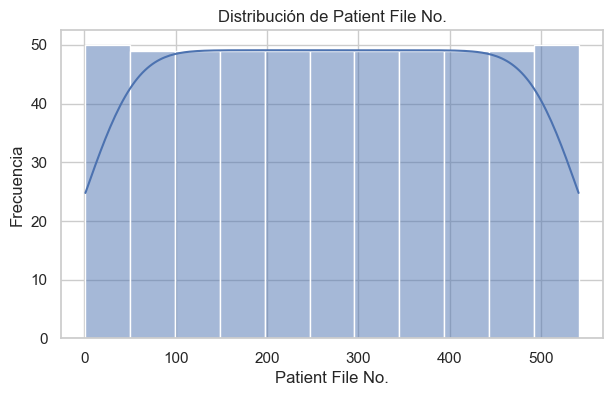

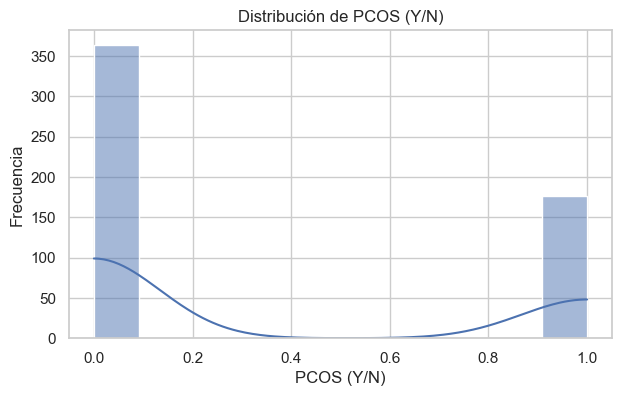

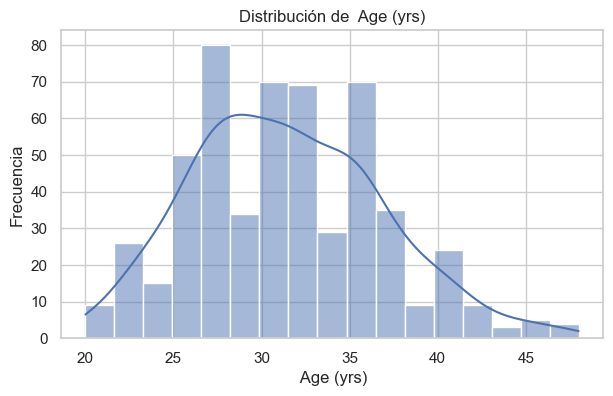

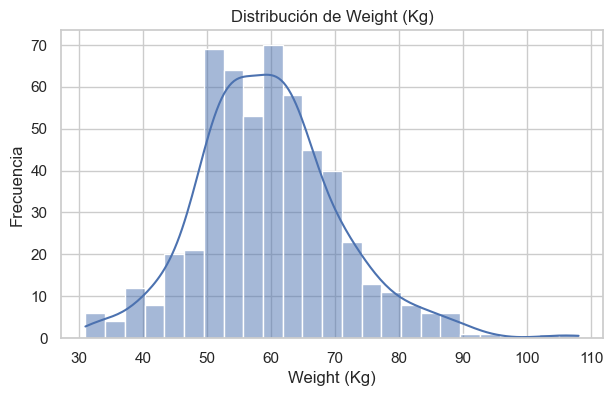

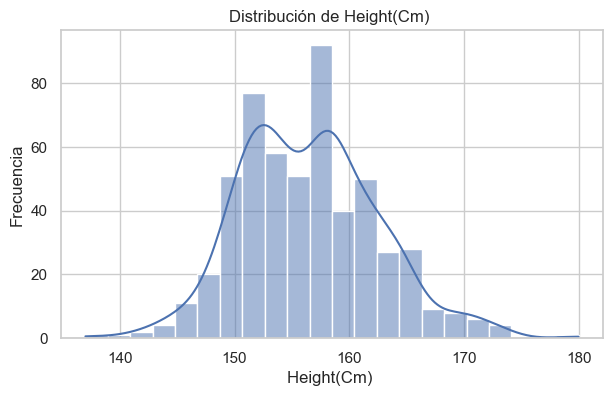

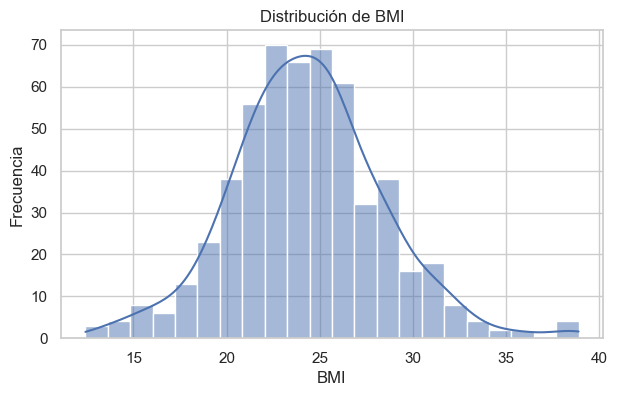

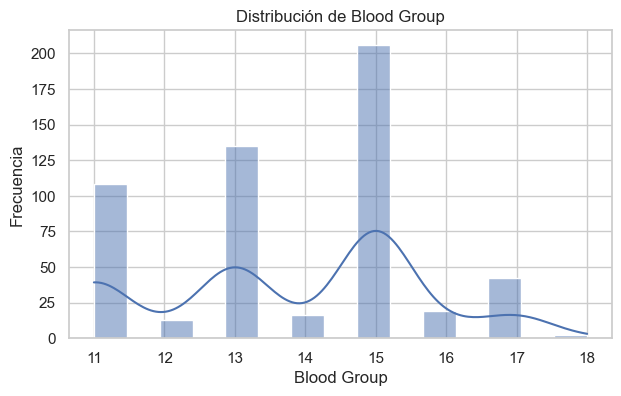

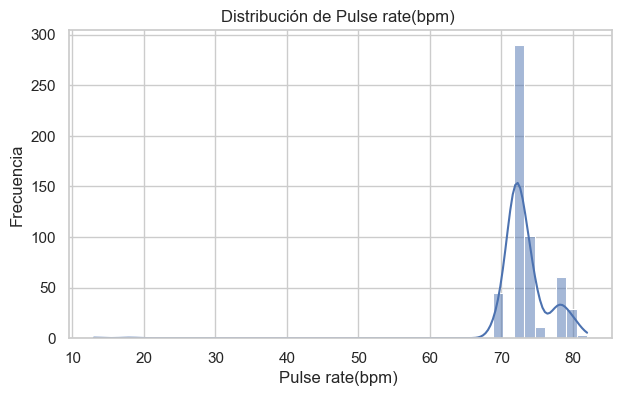

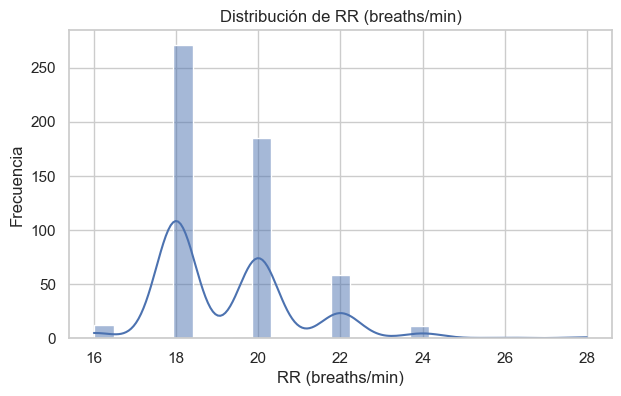

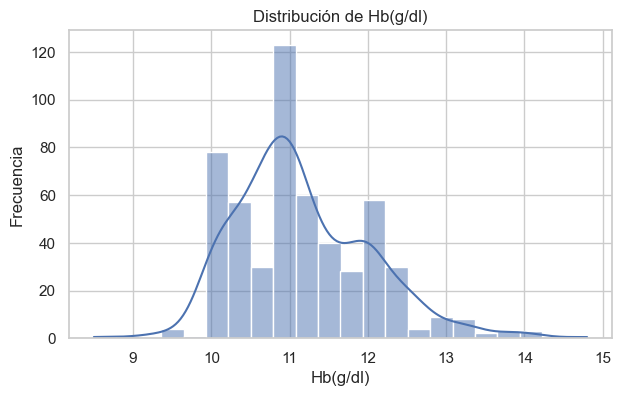

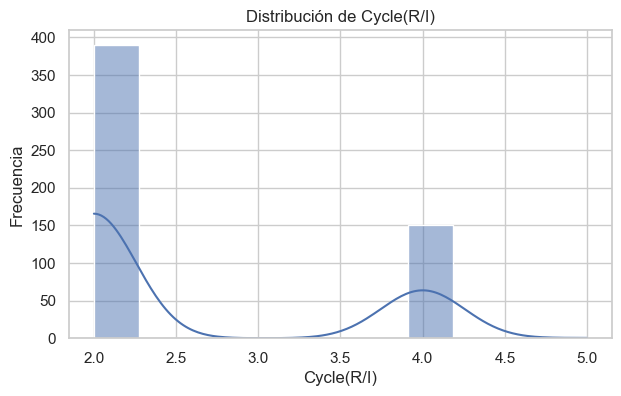

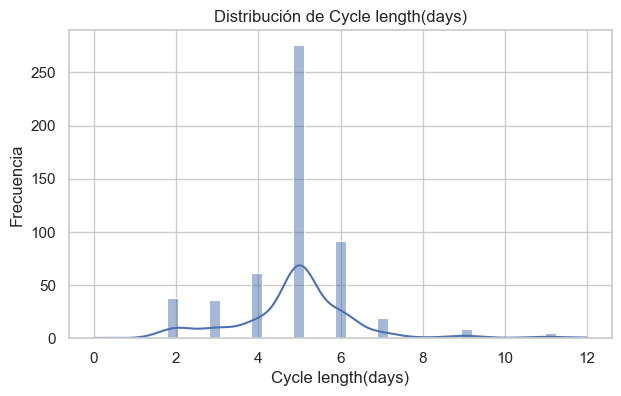

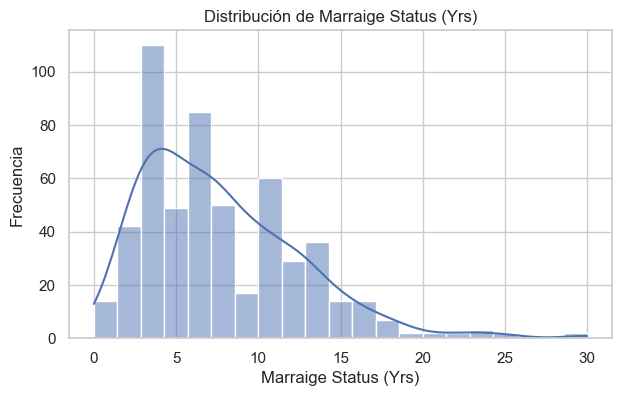

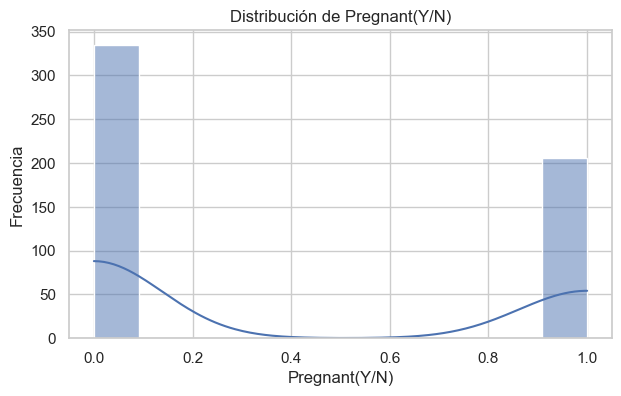

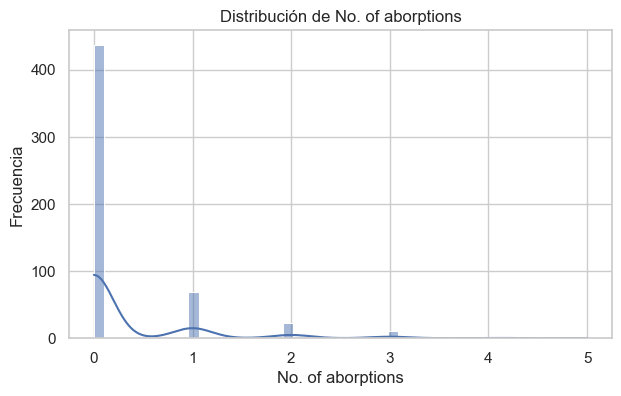

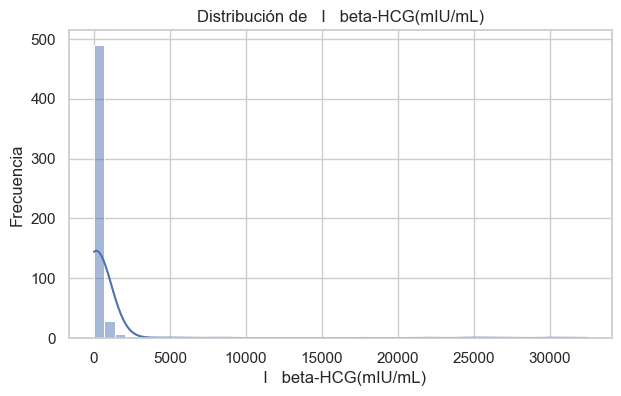

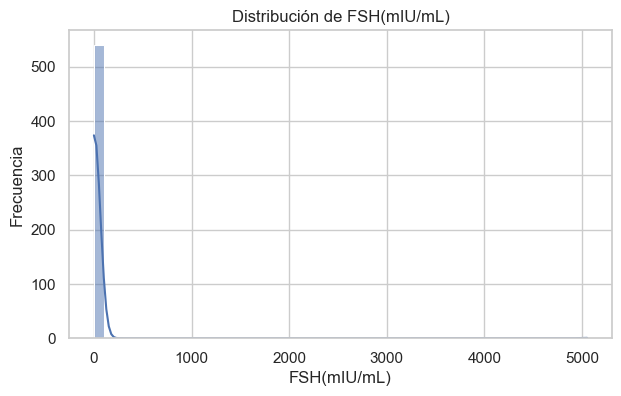

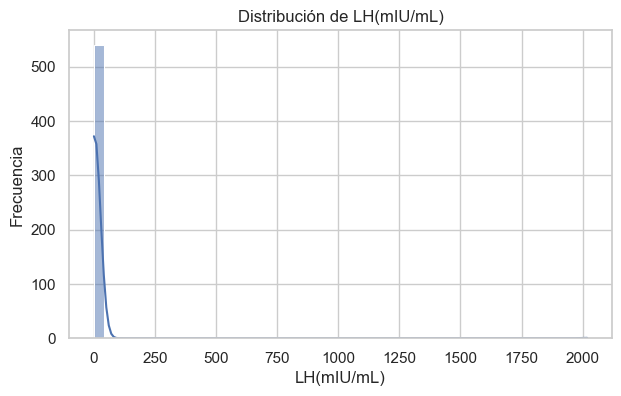

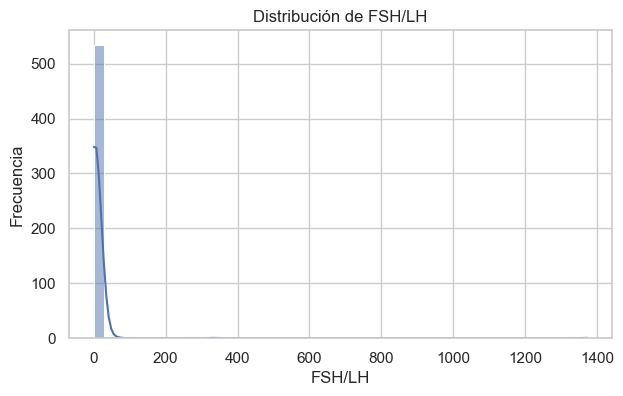

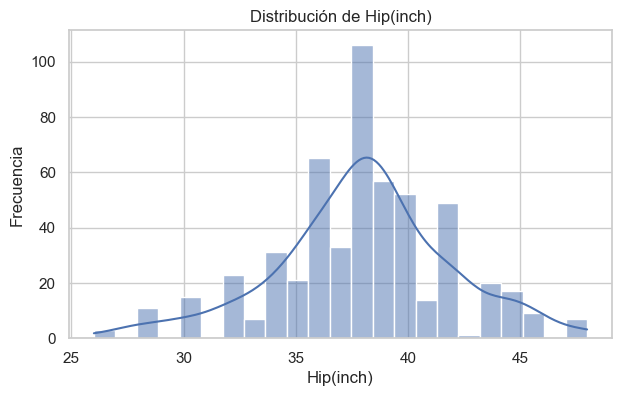

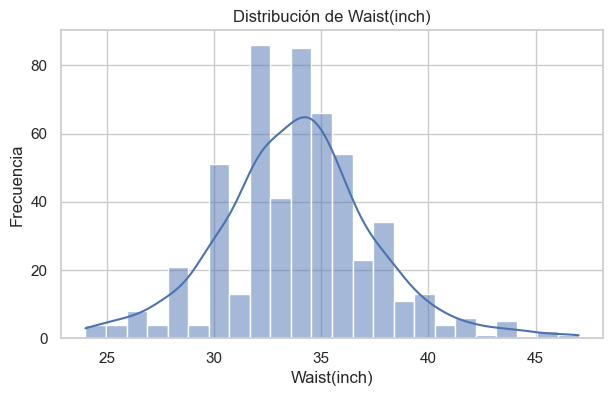

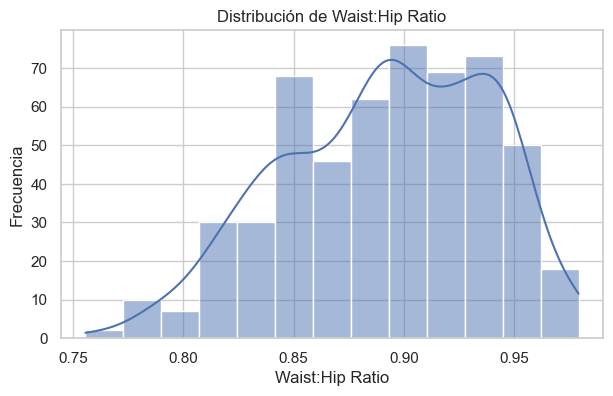

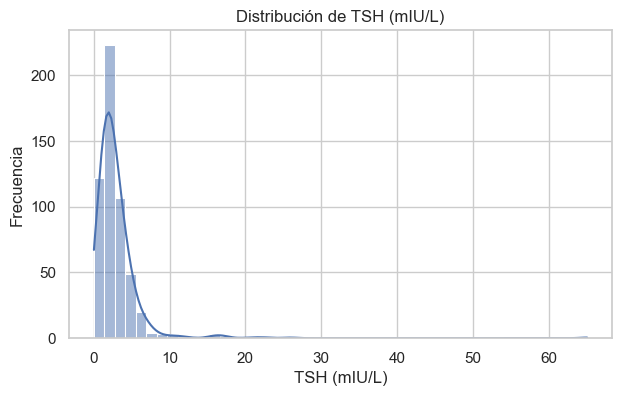

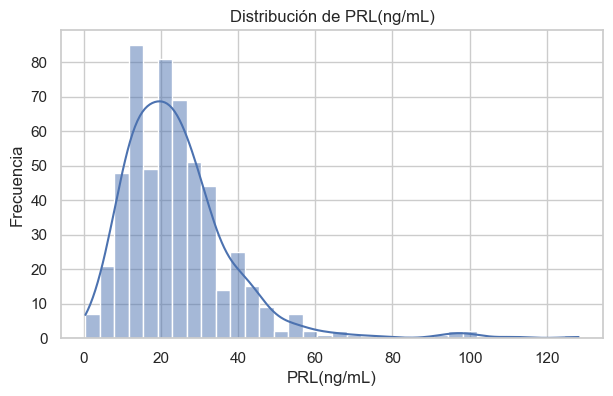

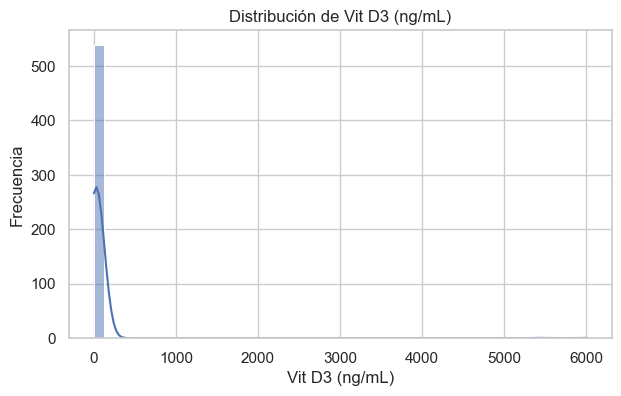

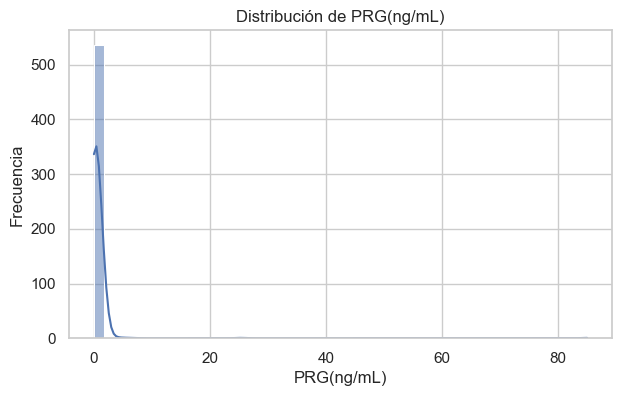

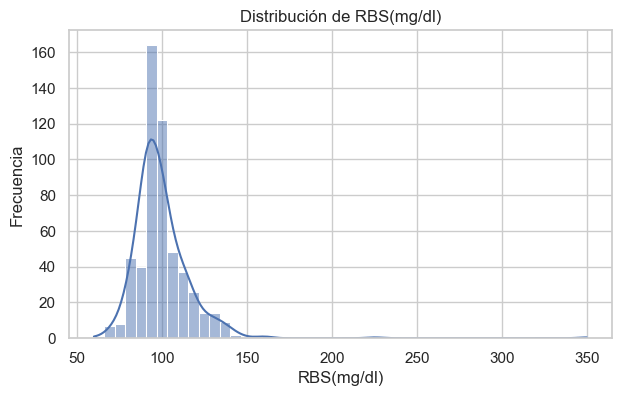

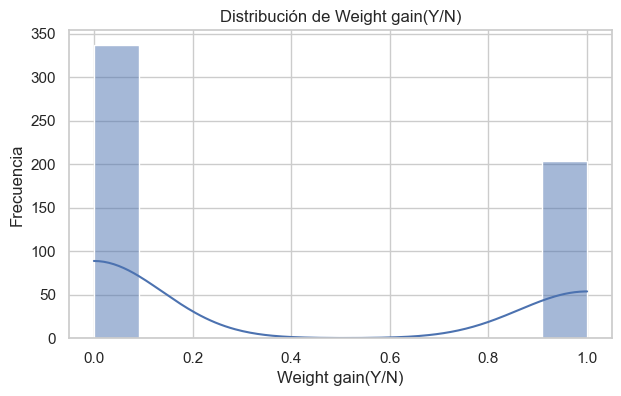

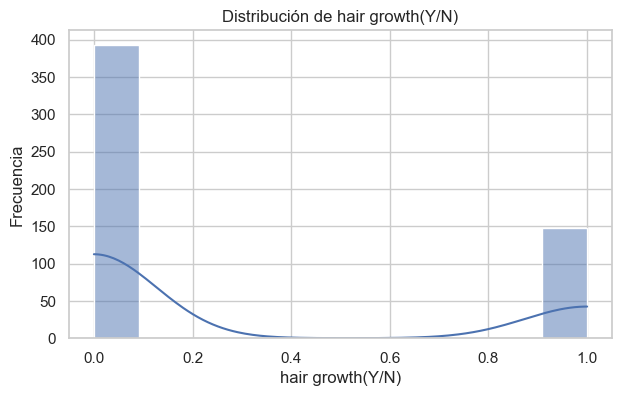

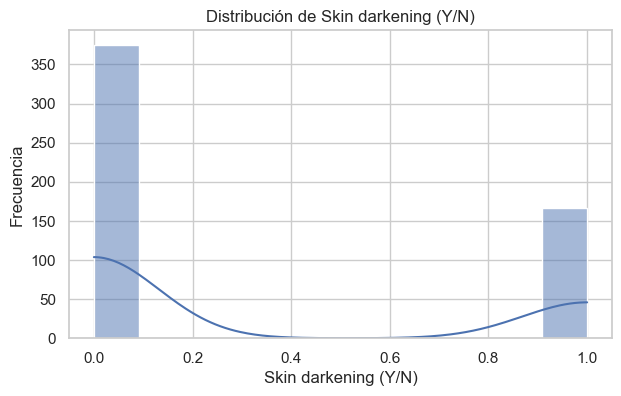

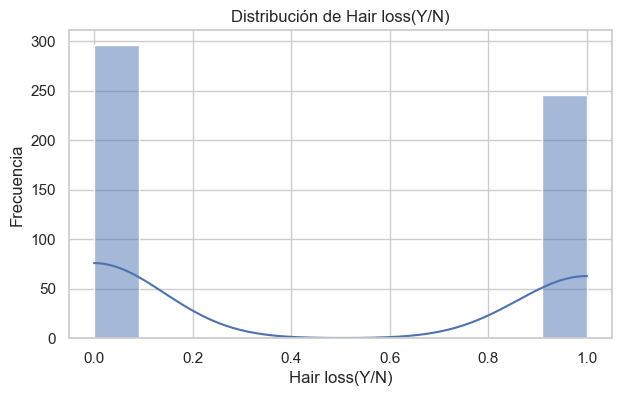

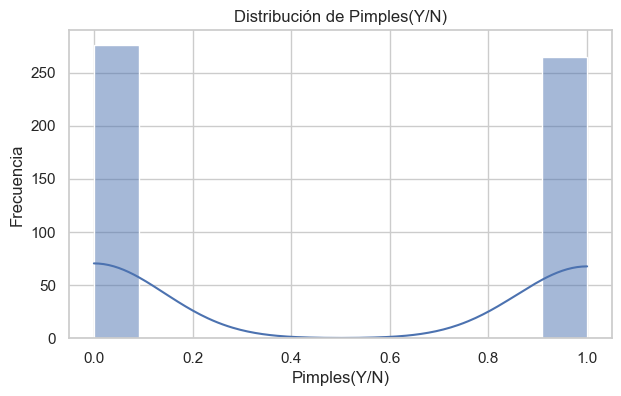

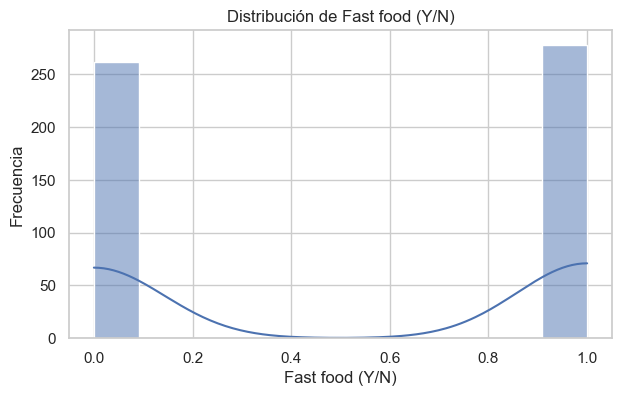

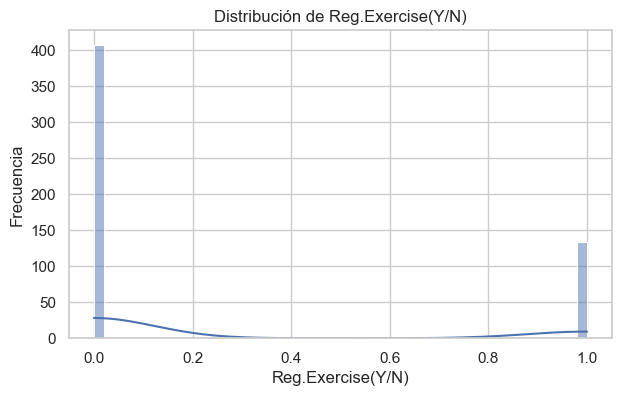

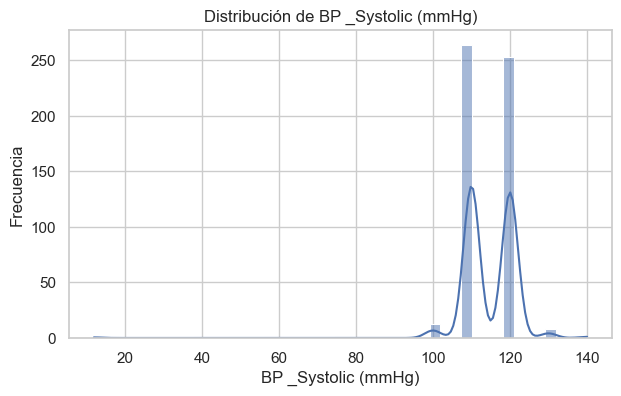

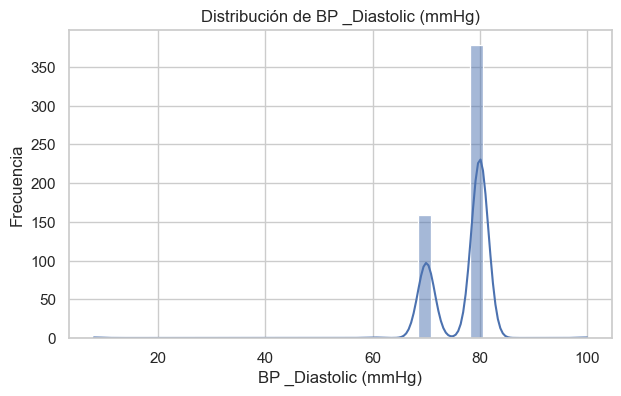

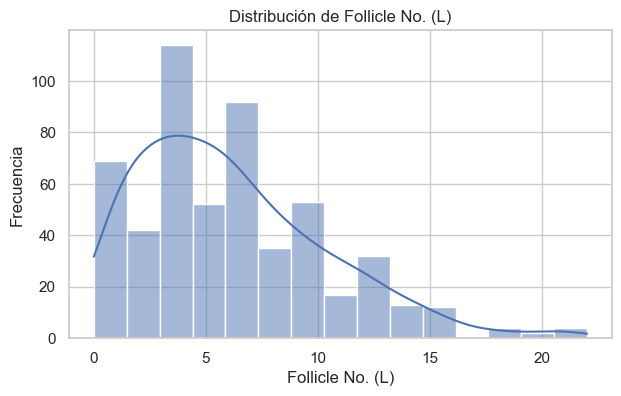

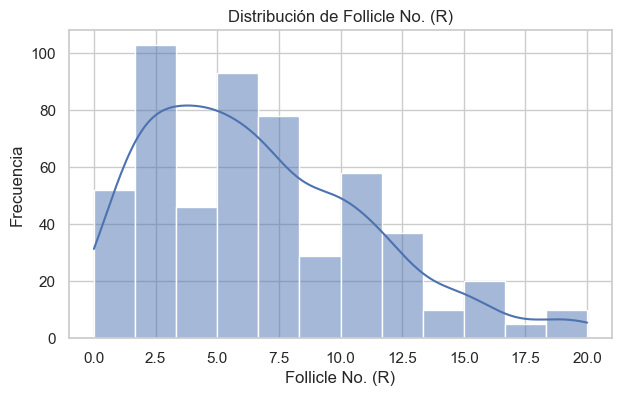

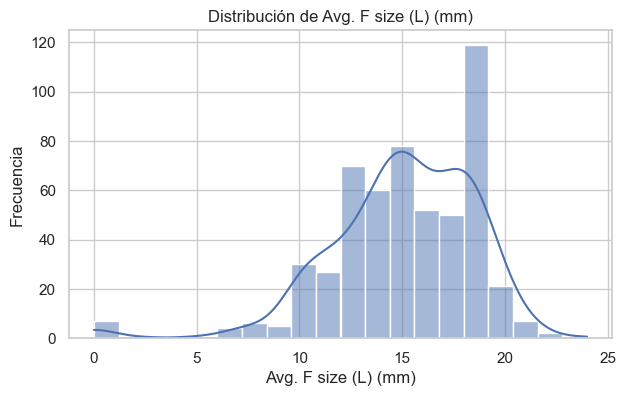

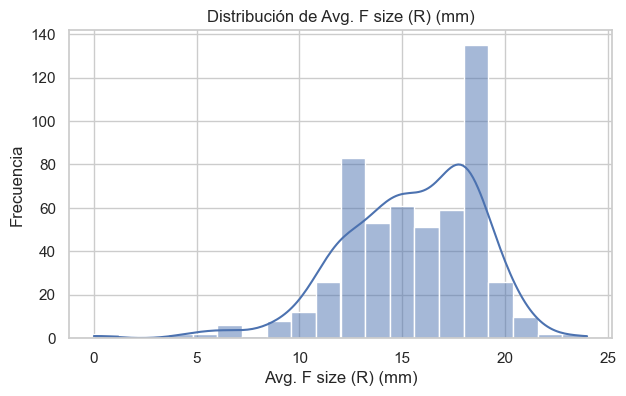

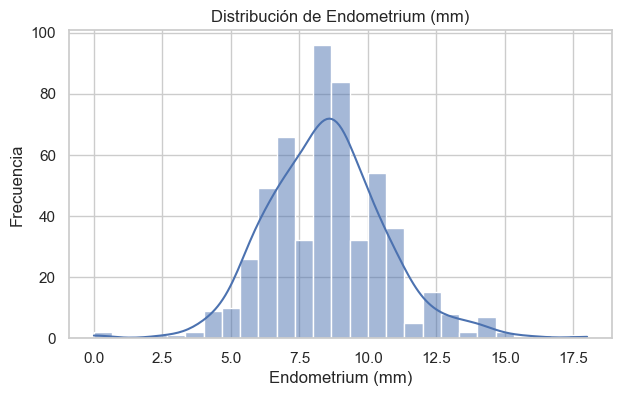

In [84]:
#Gráficos de los valores numéricos: Histogramas
for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df1,
        x=col,
        kde=True
    )

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')

    plt.show()

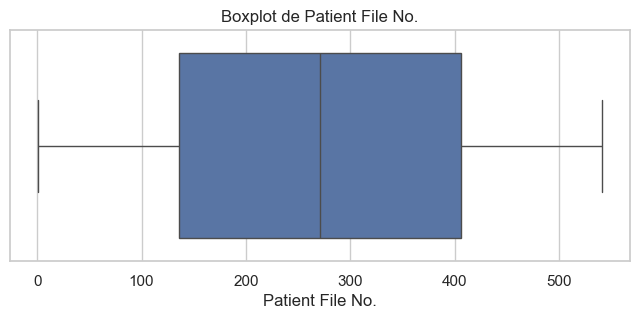

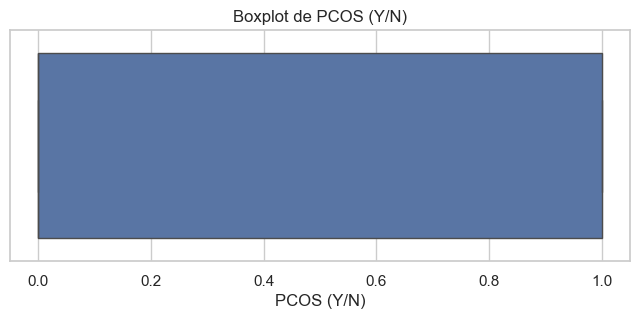

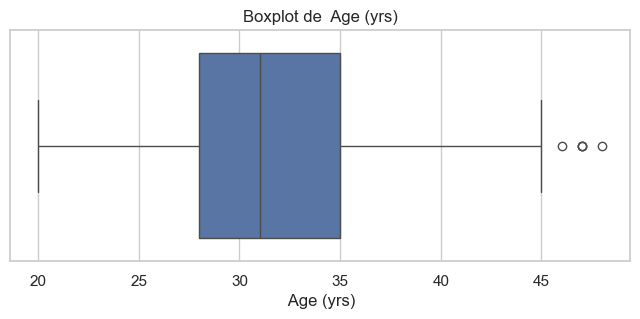

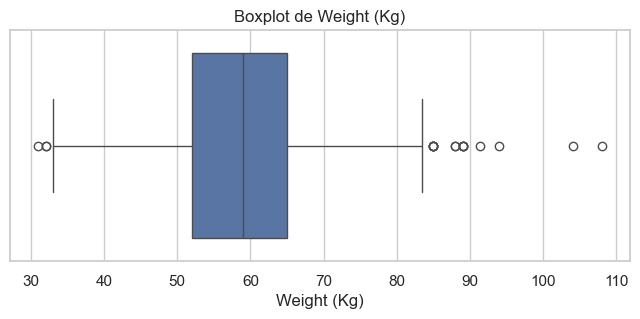

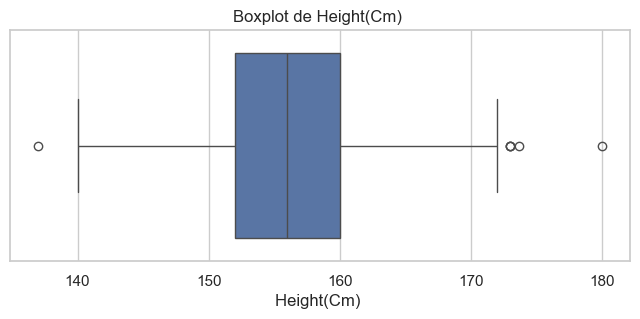

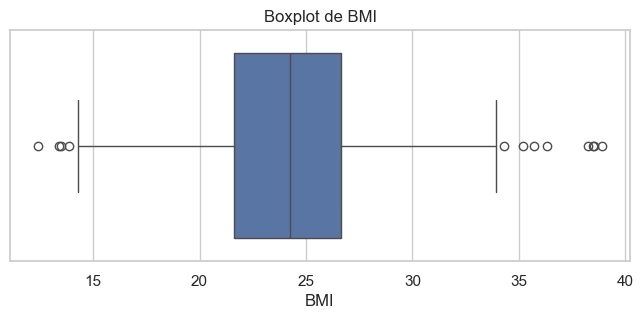

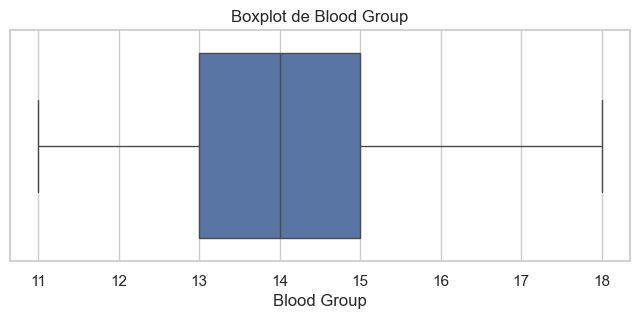

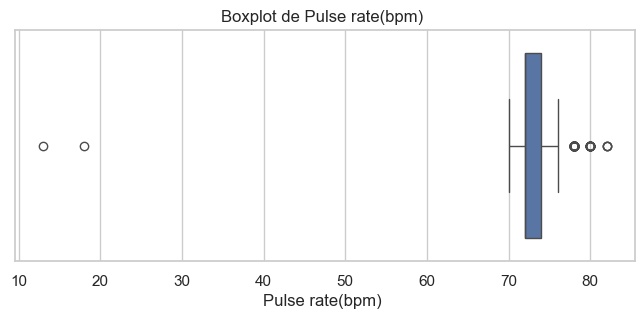

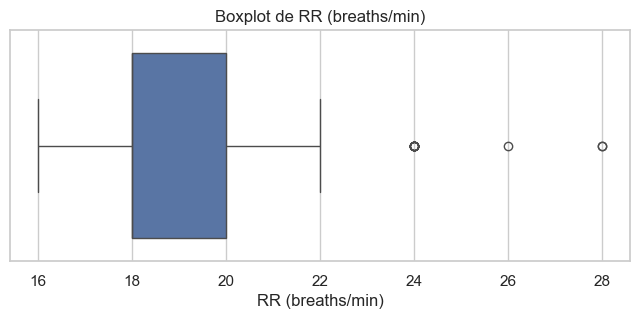

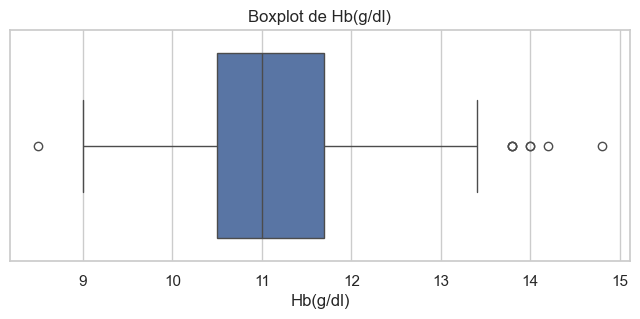

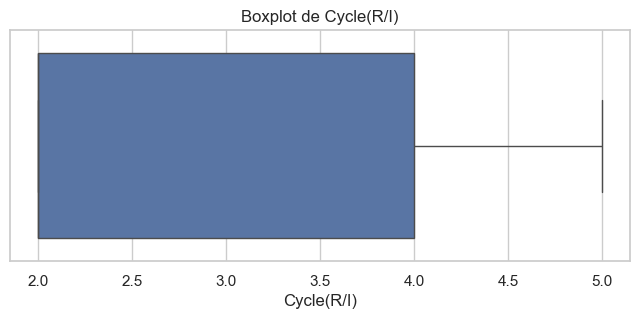

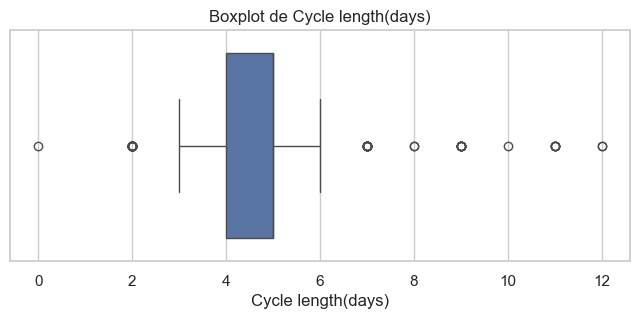

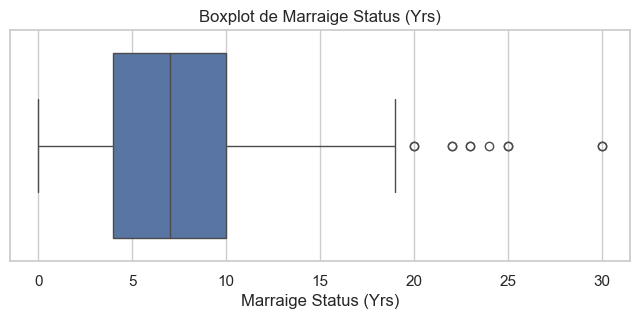

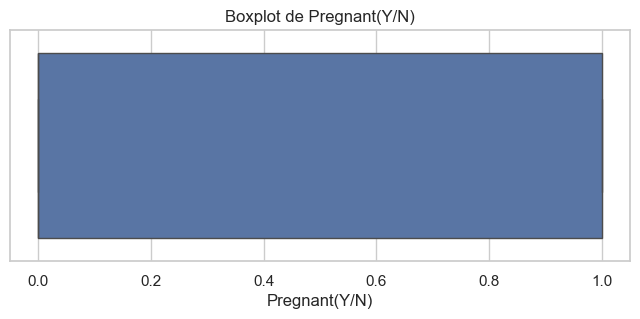

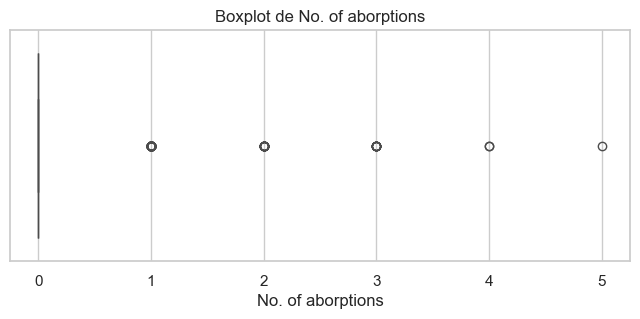

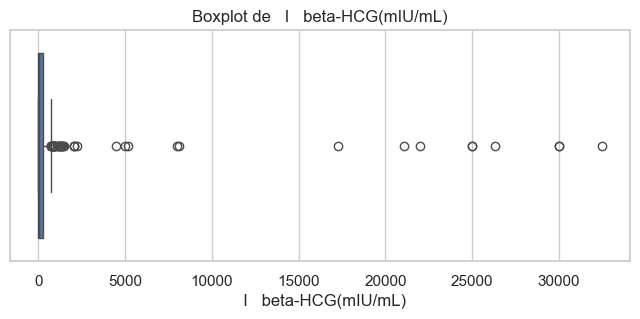

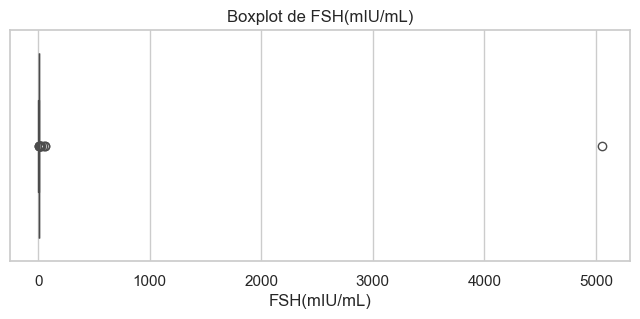

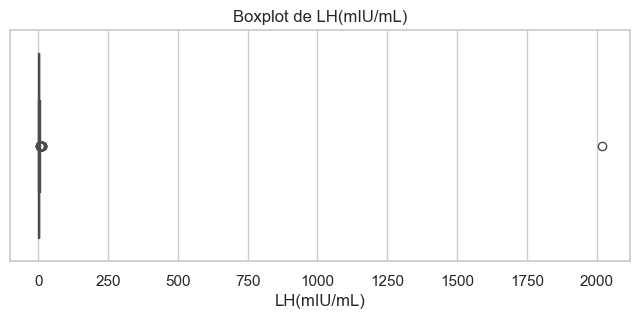

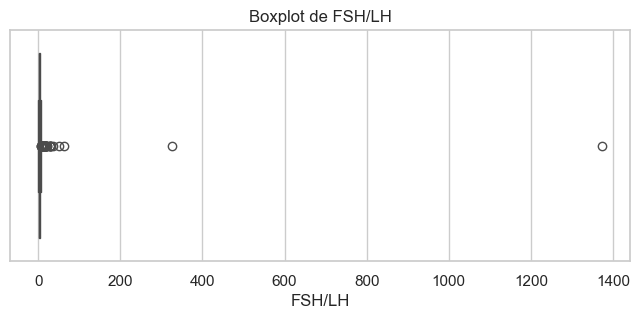

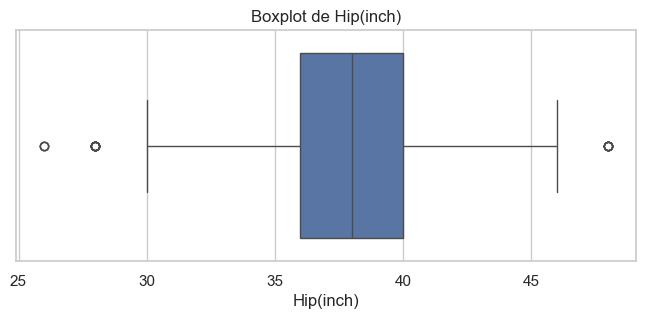

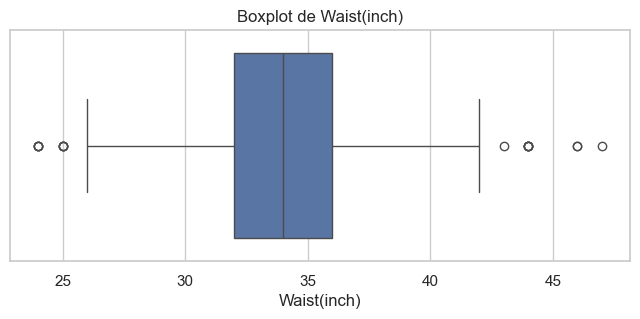

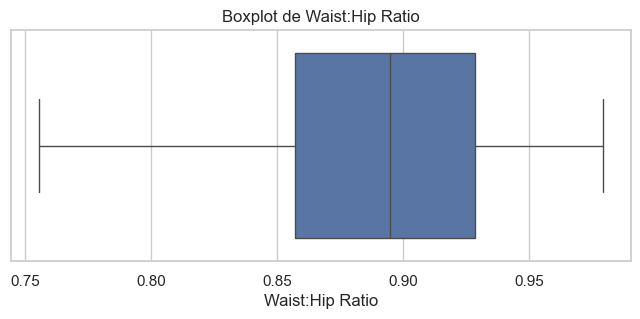

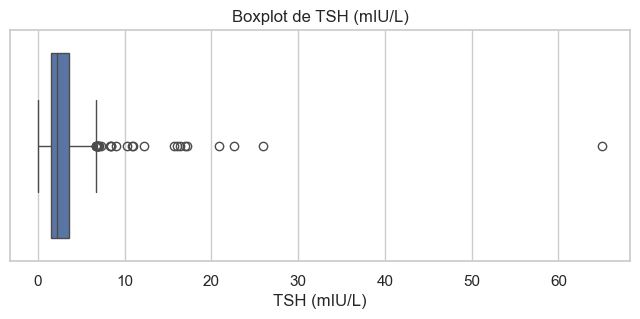

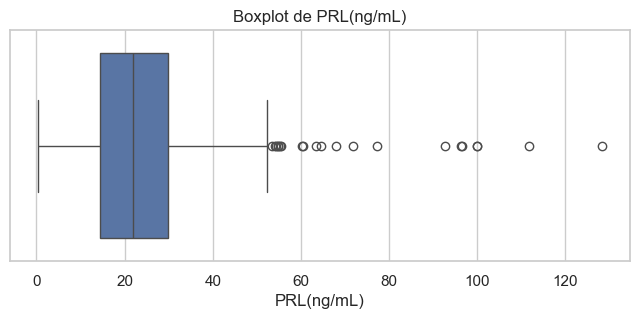

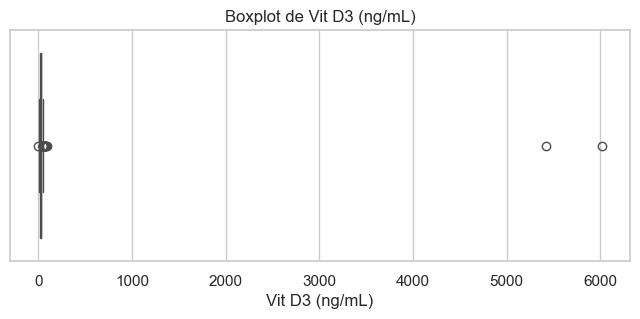

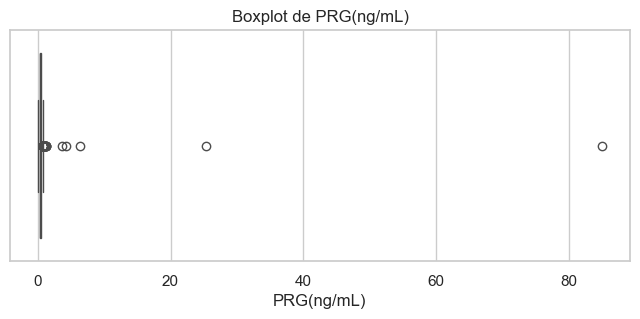

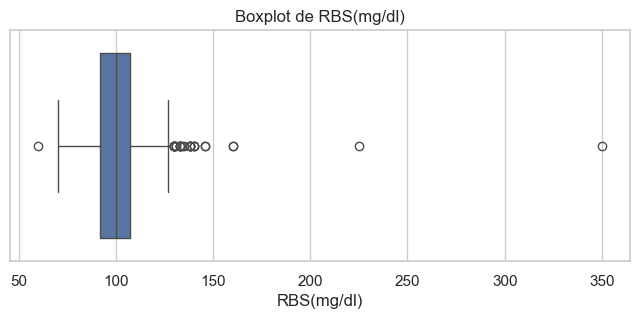

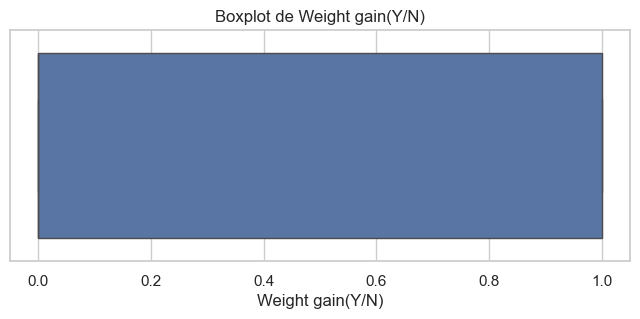

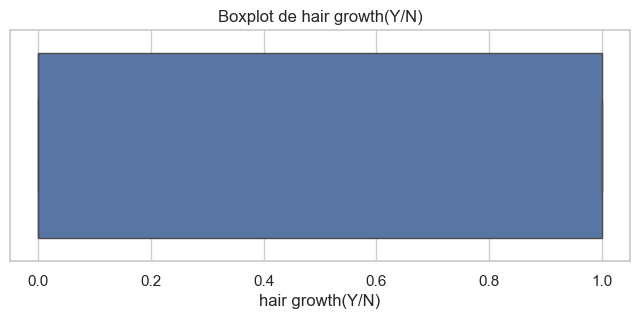

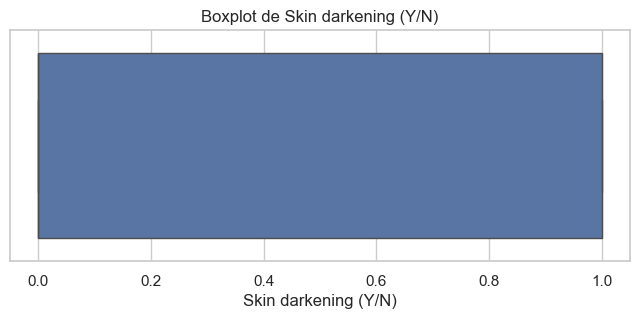

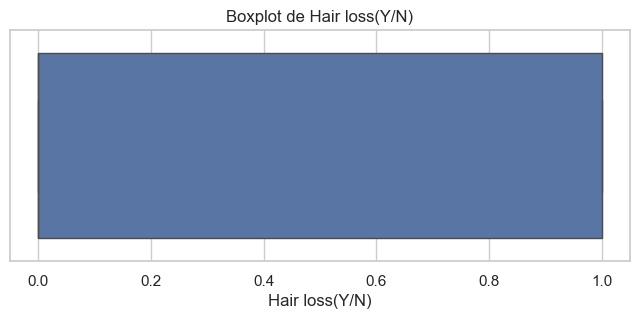

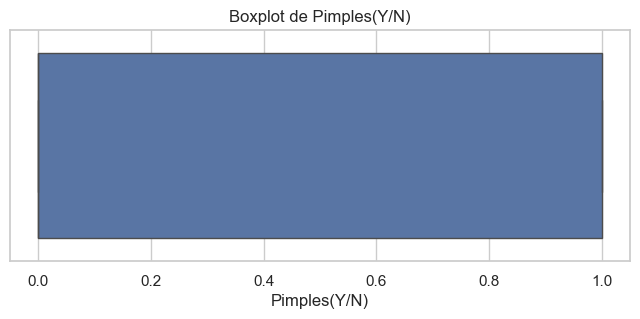

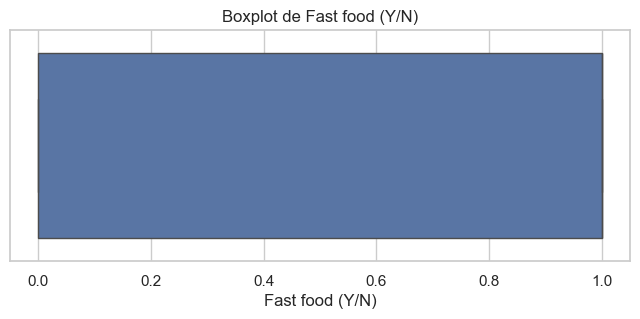

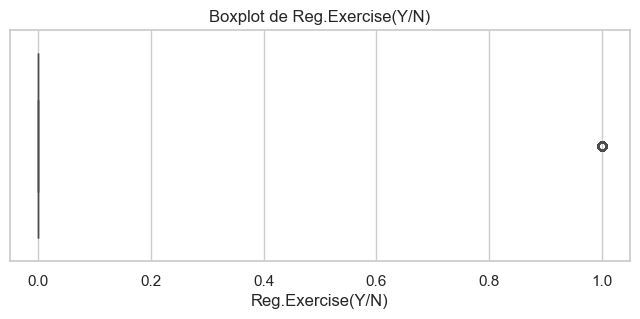

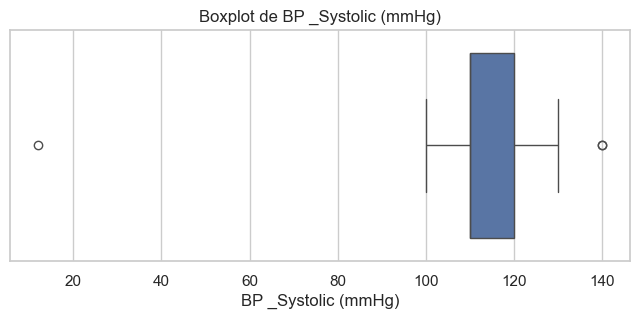

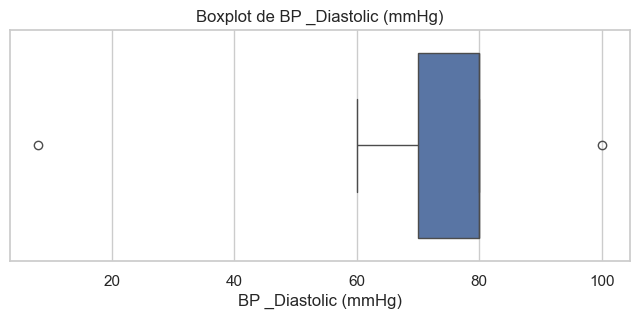

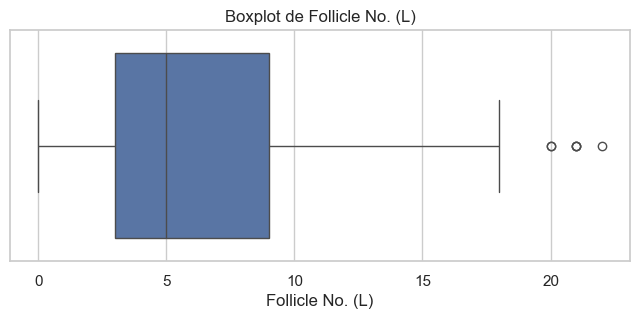

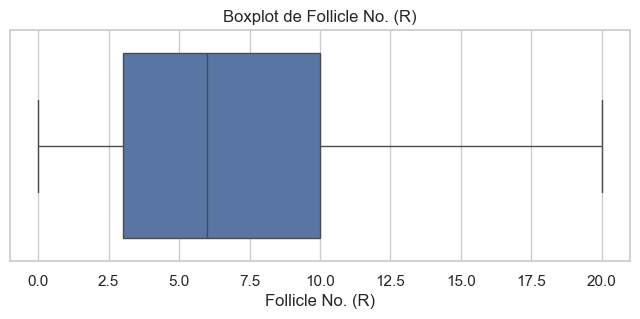

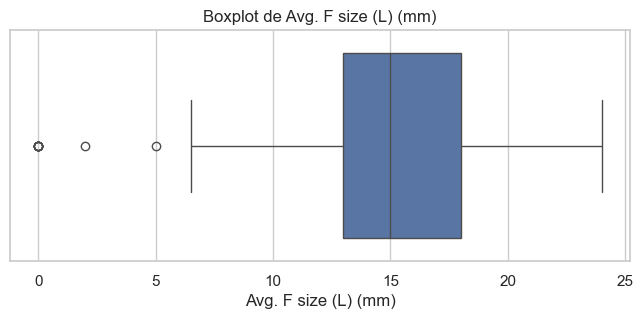

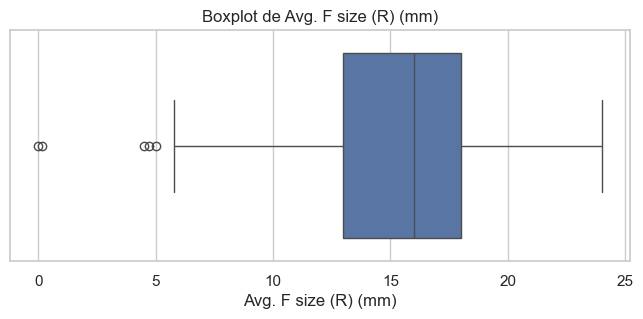

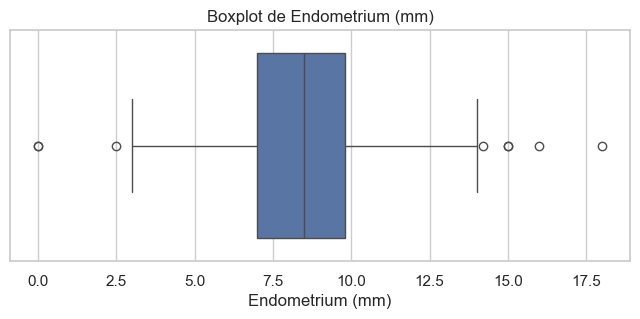

In [85]:
# Revisión de OUTLIERS: Boxplot

for col in numeric_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        x=df1[col]
    )

    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)

    plt.show()

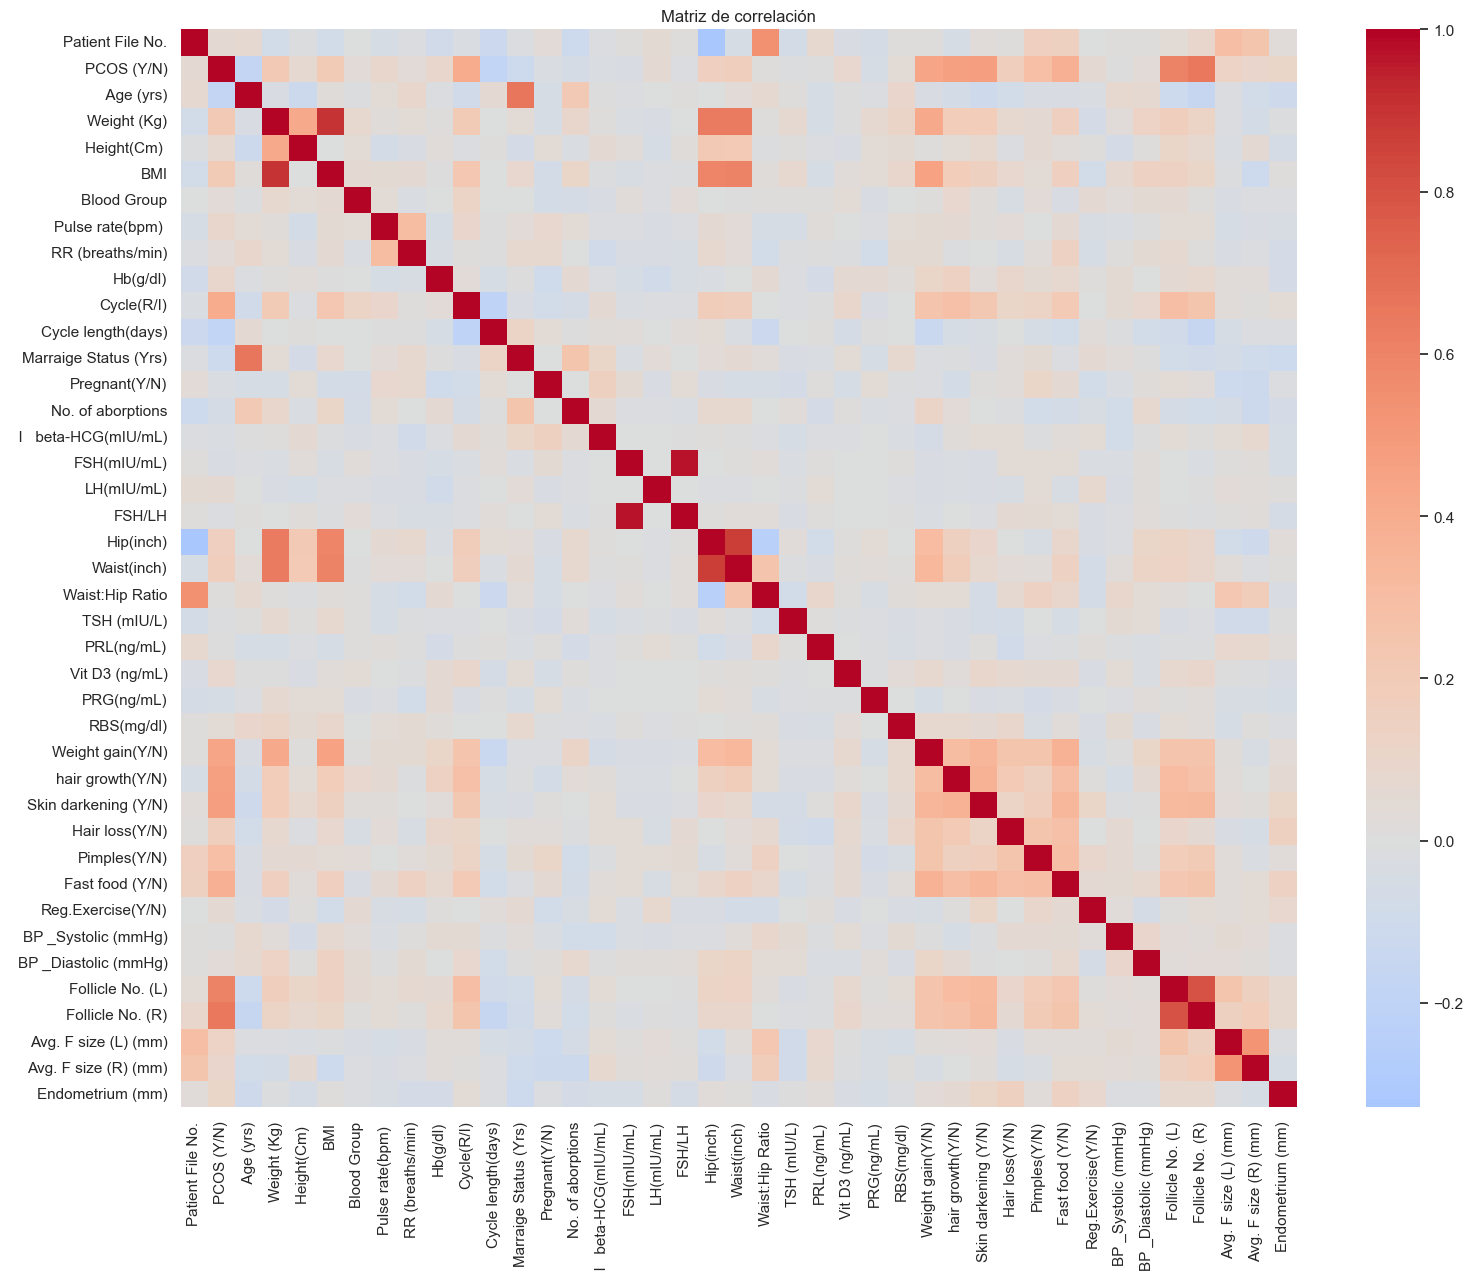

In [86]:
#  MATRIZ DE CORRELACIÓN


correlation = df1[numeric_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Matriz de correlación')

plt.show()

In [87]:
#  CORRELACIÓN CON PCOS

target_corr = (
    correlation[target]
    .sort_values(ascending=False)
)

display(target_corr)

PCOS (Y/N)                1.000000
Follicle No. (R)          0.648327
Follicle No. (L)          0.603346
Skin darkening (Y/N)      0.475733
hair growth(Y/N)          0.464667
Weight gain(Y/N)          0.441047
Cycle(R/I)                0.401644
Fast food (Y/N)           0.377933
Pimples(Y/N)              0.286077
Weight (Kg)               0.211938
BMI                       0.199534
Hair loss(Y/N)            0.172879
Waist(inch)               0.164598
Hip(inch)                 0.162297
Avg. F size (L) (mm)      0.132992
Endometrium (mm)          0.106648
Avg. F size (R) (mm)      0.097690
Pulse rate(bpm)           0.091821
Hb(g/dl)                  0.087170
Vit D3 (ng/mL)            0.085494
Height(Cm)                0.068254
Reg.Exercise(Y/N)         0.065337
LH(mIU/mL)                0.063879
Patient File No.          0.060998
RBS(mg/dl)                0.048922
BP _Diastolic (mmHg)      0.038032
RR (breaths/min)          0.036928
Blood Group               0.036433
Waist:Hip Ratio     

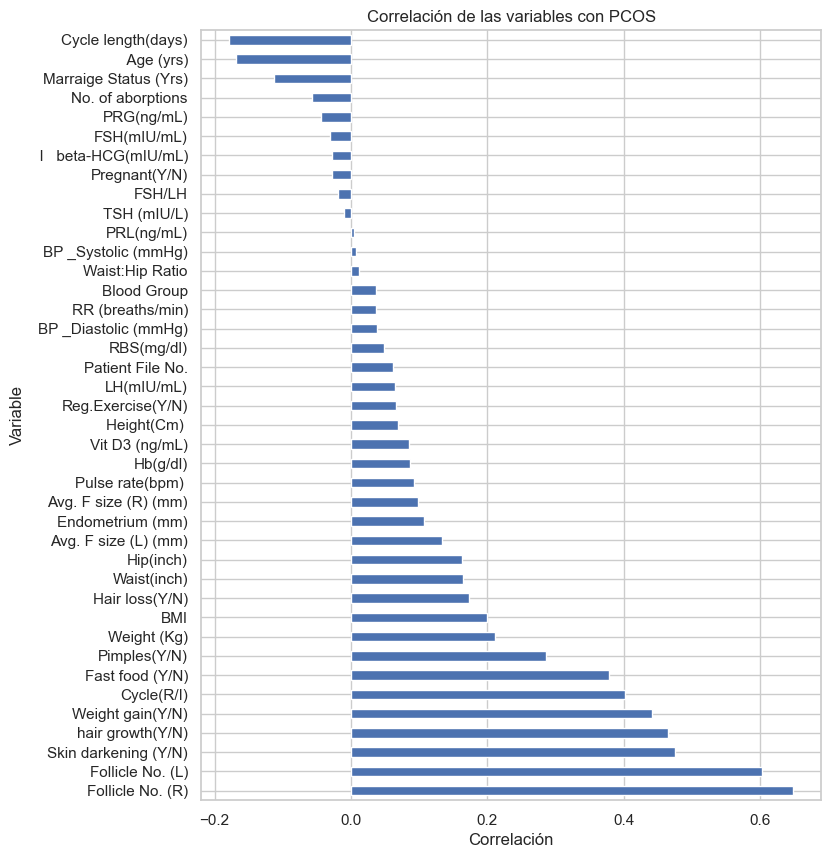

In [88]:
#Se aprecia las variables que tienen mayor peso para detección de PCOS.
#principalmente son: Follicle No (R), Follicle No (L), Skin Darkening, Hair Growth
plt.figure(figsize=(8, 10))

target_corr.drop(target).plot(
    kind='barh'
)

plt.title('Correlación de las variables con PCOS')
plt.xlabel('Correlación')
plt.ylabel('Variable')

plt.show()

In [89]:
#  RESUMEN DEL DATASET

summary = pd.DataFrame({
    'Tipo de dato': df1.dtypes,
    'Valores únicos': df1.nunique(),
    'Valores faltantes': df1.isnull().sum(),
    '% faltantes': df1.isnull().mean() * 100,
    'Duplicados': df1.duplicated().sum()
})

display(summary)

,Tipo de dato,Valores únicos,Valores faltantes,% faltantes,Duplicados
Patient File No.,int64,541,0,0.000000,0
PCOS (Y/N),int64,2,0,0.000000,0
Age (yrs),int64,29,0,0.000000,0
Weight (Kg),float64,117,0,0.000000,0
Height(Cm),float64,50,0,0.000000,0
BMI,float64,355,0,0.000000,0
Blood Group,int64,8,0,0.000000,0
Pulse rate(bpm),int64,11,0,0.000000,0
RR (breaths/min),int64,8,0,0.000000,0
Hb(g/dl),float64,46,0,0.000000,0


### 3-LIMPIEZA DE DATOS

In [90]:
# CREAR COPIA DEL DATASET

df_clean = df1.copy()

print("Dataset original:", df1.shape)
print("Copia para limpieza:", df_clean.shape)

Dataset original: (541, 44)
Copia para limpieza: (541, 44)


In [91]:
# DETECTAR VALORES FALTANTES: aquí se estandariza los valores vacíos a un práctico np.nan
# que posteriormente nos permitirá tomar la decisión de como reemplazar esos datos por algo más.

missing_values = ['?', 'NA', 'N/A', 'na', 'n/a', '', ' ']

df_clean = df_clean.replace(
    missing_values,
    np.nan
)

print("Valores faltantes después de la conversión:")
display(df_clean.isnull().sum().sort_values(ascending=False))

Valores faltantes después de la conversión:


Unnamed: 44               539
Marraige Status (Yrs)       1
Fast food (Y/N)             1
PRL(ng/mL)                  0
Vit D3 (ng/mL)              0
PRG(ng/mL)                  0
RBS(mg/dl)                  0
Weight gain(Y/N)            0
hair growth(Y/N)            0
Skin darkening (Y/N)        0
Hair loss(Y/N)              0
Pimples(Y/N)                0
TSH (mIU/L)                 0
Reg.Exercise(Y/N)           0
BP _Systolic (mmHg)         0
BP _Diastolic (mmHg)        0
Follicle No. (L)            0
Follicle No. (R)            0
Avg. F size (L) (mm)        0
Avg. F size (R) (mm)        0
Endometrium (mm)            0
AMH(ng/mL)                  0
Patient File No.            0
PCOS (Y/N)                  0
Cycle(R/I)                  0
 Age (yrs)                  0
Weight (Kg)                 0
Height(Cm)                  0
BMI                         0
Blood Group                 0
Pulse rate(bpm)             0
RR (breaths/min)            0
Hb(g/dl)                    0
Cycle leng

In [92]:
# Del análisis exploratorio (EDA) nos dimos cuenta que existen 2 columnas numéricas que tienen el tipo de dato
# "object", por lo tanto, aquí se optó por pasarlo a numérico.

df_clean['II    beta-HCG(mIU/mL)'] = pd.to_numeric(
    df_clean['II    beta-HCG(mIU/mL)'],
    errors='coerce'
)

df_clean['AMH(ng/mL)'] = pd.to_numeric(
    df_clean['AMH(ng/mL)'],
    errors='coerce'
)

In [93]:
#aquí se identifica que columns queremos eliminar: Definitivamente Unnamed: 44 es un error del dataset, por lo que se v
# además, Patient File no. Es un ID que también se eliminará ya que no aporta nada al aprendizaje.
# se selecciona la variable de salida PCOS (Y/N) y se guardan estos datos en X , y para dejarlas listas para
# el aprendizaje.
target = 'PCOS (Y/N)'
features_to_drop = ['Patient File No.', "Unnamed: 44"]
X = df_clean.drop(columns=[target] + features_to_drop)
y = df_clean[target]

print("X:", X.shape)
print("y:", y.shape)

print("\nVariables utilizadas:")
print(X.columns.tolist())


X: (541, 41)
y: (541,)

Variables utilizadas:
[' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


In [94]:
# También, de los datos se intuyó que existen 2 columans que potencialmente son categóricas. Dichas columnas son
# Blood group y Cycle (R/I)

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categorical_features.extend([
    'Blood Group',
    'Cycle(R/I)'
])

numeric_features = [
    col for col in numeric_features
    if col not in categorical_features
]


print("VARIABLES NUMÉRICAS:")
print(numeric_features)

print("\nVARIABLES CATEGÓRICAS:")
print(categorical_features)

VARIABLES NUMÉRICAS:
[' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

VARIABLES CATEGÓRICAS:
['Blood Group', 'Cycle(R/I)']


In [95]:
# Por último en la limpieza de datos, se encontró que ENCODE CYCLE(R/I) es como binario, pero con valores 2 y 4.
#Por lo que se reemplazará por 0 y 1 para tener congruencia con el resto de las columnas.

X['Cycle(R/I)'] = X['Cycle(R/I)'].map({
    2: 0,   # Regular
    4: 1    # Irregular
})

print(X['Cycle(R/I)'].value_counts(dropna=False))

Cycle(R/I)
0.0    390
1.0    150
NaN      1
Name: count, dtype: int64


### 4-MODELO BASE BASELINE

In [96]:
# Se hace la partición Train/test. Se usa un porcentaje de test de 20% ya que al ser relativamente pocos datos
# se busca tener un porcentaje mayor en train para el aprendizaje.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (432, 41)
Test set: (109, 41)


In [97]:
# Se hace un pipeline sencillo con las siguientes variables relevantes:
#SimpleEmputer para rellenar los valores faltantes.
#StandardScaler para lidiar con los outliers
#OnehotEncoder para convertir en 0 y 1 las categorías de Blood group

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# NUMÉRICOS
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# CATEGÓRICOS
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore'
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [98]:
#Como modelo baseline se optó por LogisticRegression. En este primer alcance no se modificarán
#hyperparametros ya que se buscará en actividades futuras monitorear como va evolucionando la métrica

from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [99]:
# Se entrena el modelo

baseline_model.fit(
    X_train,
    y_train
)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [100]:
# Predicción

y_pred = baseline_model.predict(X_test)

y_prob = baseline_model.predict_proba(X_test)[:, 1]

In [101]:
# Métricas

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("BASELINE RESULTS")
print("=" * 40)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

BASELINE RESULTS
Accuracy : 0.9083
Precision: 0.8421
Recall   : 0.8889
F1 Score : 0.8649
ROC-AUC  : 0.9490


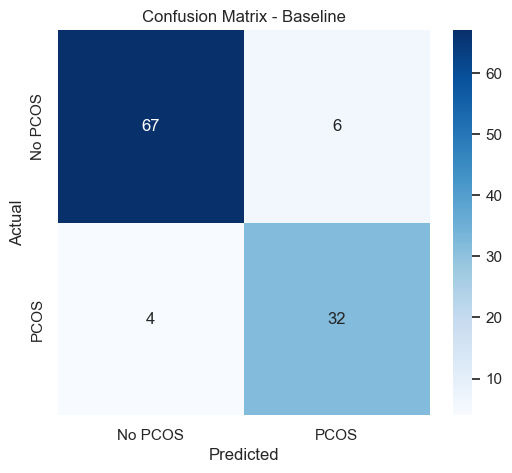

In [102]:
#Matriz de confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No PCOS', 'PCOS'],
    yticklabels=['No PCOS', 'PCOS']
)

plt.title('Confusion Matrix - Baseline')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### 5.1 Interpretación de los resultados:

A pesar de ser un modelo baseline donde no se enfocó en optimizar los hyperparámetros. Se tuvo un resultado inicial bastante bueno. El punto de comparación con un modelo "dummy" es la proporción de datos inicial de 0.6728 (asumiendo que siempre el modelo trata de adivinar la clase mayoritaria). La métrica que se usará principalmente para comparación es precision, ya que para un problema de carácter médico es más importante detectar casos positivos a costa de tener más falsos positivos. En este momento se obtuvo 0.8421. Esta métrica se buscará mejorar en siguientes entregas.

### 6-REGISTRO DE EXPERIMENTO EN MLFLOW

In [103]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("PCOS_Classification")

<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1791146003295, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1791146003295, lifecycle_stage='active', name='PCOS_Classification', tags={}, trace_location=None, workspace='default'>

In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

with mlflow.start_run(run_name="baseline_logistic_regression"):

    # ========================================
    # PARAMETERS
    # ========================================

    mlflow.log_param(
        "model",
        "Logistic Regression"
    )

    mlflow.log_param(
        "test_size",
        0.20
    )

    mlflow.log_param(
        "random_state",
        42
    )

    mlflow.log_param(
        "max_iter",
        1000
    )

    mlflow.log_param(
        "scaler",
        "StandardScaler"
    )

    mlflow.log_param(
        "numeric_imputation",
        "median"
    )

    mlflow.log_param(
        "categorical_encoding",
        "OneHotEncoder"
    )

    # ========================================
    # METRICS
    # ========================================

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("roc_auc", roc_auc)

    # ========================================
    # MODEL
    # ========================================

    mlflow.sklearn.log_model(
        baseline_model,
        name="baseline_model",
        serialization_format="cloudpickle"
    )

    print("Experiment registered successfully.")

2026/10/04 14:37:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Experiment registered successfully.
🏃 View run baseline_logistic_regression at: http://127.0.0.1:5000/#/experiments/3/runs/7043cae08c414d8289db97c80a1529a4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### 7-REFLEXION FINAL

![alt text](image-1.png)

El desarrollo de este proyecto permitió comprender que construir un modelo de Machine Learning no consiste únicamente en entrenar un algoritmo y obtener una métrica de precisión, sino en desarrollar un flujo reproducible, medible y fácil de mantener. En este caso, se realizó el procesamiento de un conjunto de datos de pacientes con PCOS, la selección y transformación de variables, el entrenamiento de un modelo de regresión logística y la evaluación mediante métricas como accuracy, precision, recall, F1-score y ROC-AUC. Además, mediante MLflow fue posible registrar los parámetros, métricas y modelos obtenidos, lo cual representa un primer acercamiento a las prácticas de MLOps.
Para mejorar este flujo, implementaría un pipeline completamente automatizado que incluya validación de datos, versionamiento del dataset y del código, diferentes experimentos de modelos y hyperparameter tuning. También incorporaría pruebas automatizadas, monitoreo del desempeño del modelo y detección de data drift para identificar cuándo el modelo comienza a perder confiabilidad. Finalmente, integraría un proceso de CI/CD que permita validar y desplegar nuevas versiones del modelo de manera controlada.
Estos aprendizajes tienen una relación directa con mi área profesional como ingeniero civil. En ingeniería estructural y de infraestructura se trabaja constantemente con grandes cantidades de información provenientes de estudios, proyectos, sensores, costos y modelos numéricos. Las prácticas de MLOps pueden ayudar a desarrollar herramientas que automaticen análisis, detecten patrones y apoyen la toma de decisiones, pero manteniendo trazabilidad, reproducibilidad y control sobre los resultados. De esta manera, MLOps no solamente permite crear mejores modelos, sino integrarlos de manera confiable dentro de procesos profesionales reales.